In [1]:
import pymc as pm
import pytensor.tensor as pt
import numpy as np
import matplotlib.pyplot as plt # графики

g++ not available, if using conda: `conda install gxx`


In [2]:
# Объявляем константы

vector3 = np.ndarray

cm = 1
m = 100*cm

golden_ratio_minus_1 = 2/(1+pt.sqrt(5)) # Распределение фотоумножители сделано по спирали Фибоначчи, поэтому нам нужно вот такое число

keV = 1e-3
MeV = 1

In [3]:
def GetPMTCoords(R, N, r):

    beta = (pt.pi-pt.arcsin(r/R))/2
    delta_h = r/pt.tan(beta)
    R_photo = R-delta_h

    # Алгоритм по распределению дететкоров по сфере взят из https://arxiv.org/pdf/0912.4540

    N_points = (N-1)/2

    if (N_points % 1 == 0):

        indices = pt.arange(-N_points, N_points+1)
        
    else:

        indices = pt.arange(pt.floor(-N_points), N_points)

    # Изначально задаются сферические углы (тета сдвинут на пи пополам, чтобы покрыть верхнюю и нижнюю полусферы)
    
    theta = pt.arcsin(2*indices/N)+pt.pi/2
    phi = 2*pt.pi*indices*golden_ratio_minus_1

    # Задаётся массив декартовых координат фотокатодов

    photo_coords = R_photo*np.array([pt.sin(theta)*pt.cos(phi), pt.sin(theta)*pt.sin(phi), pt.cos(theta)]).T

    return photo_coords

#### Как определить, попал ли фотон с координатами $(x_0, y_0, z_0) = \vec{r_0}$ и вектором направления $(n_x, n_y, n_z) = \vec{n}$ в ФЭУ?

Известно, что параметризация прямой при заданных $\vec{r_0}, \vec{n}$ выглядит как $\vec{r} = \vec{r_0}+\vec{n}t$
Необходимо найти t при котором $r^2=R$:

$x^2+y^2+z^2-R^2 = (x_0+n_xt)^2+(y_0+n_yt)^2+(z_0+z_xt)^2-R^2 = (n_x^2+n_y^2+n_z^2)t^2+2(x_0n_x+y_0n_y+z_0n_z)t-R^2+y_0^2+x_0^2+z_0^2=t^2+2(\vec{r_0}, \vec{n})t-R^2+r_0^2=0$

Решая квадратное уравнение, получаем:
$t=-(\vec{r_0}, \vec{n})+\sqrt{(\vec{r_0}, \vec{n})^2+R^2-r_0^2}$

Подставив, полученное t в параметризацию, найдём координаты пересечения траектории фотона со сферой. Далее можно применить функцию, определяющую принадлежит ли точка на поверхности ФЭУ

In [4]:
def GeneratePhotonEndPoint(source_coords : vector3, direction : vector3, R : float):

    x_dir, y_dir, z_dir = direction
        
    source_coord_norm2 = pt.linalg.norm(source_coords)**2
    scalar_product = source_coords[0]*x_dir + source_coords[1]*y_dir + source_coords[2]*z_dir
    Discr = scalar_product**2+R**2-source_coord_norm2
    root = -scalar_product+pt.sqrt(Discr)

    EndPointX = source_coords[0] + x_dir*root
    EndPointY = source_coords[1] + y_dir*root
    EndPointZ = source_coords[2] + z_dir*root

    return [EndPointX, EndPointY, EndPointZ]

In [5]:
def IsCloseToPMT(EndPoint : vector3, photo_coords : vector3, r : float): # Проверка, попал ли фотон на ФЭУ

    RelX = photo_coords[0]-EndPoint[0]
    RelY = photo_coords[1]-EndPoint[1]
    RelZ = photo_coords[2]-EndPoint[2]
    
    DistancesSq = RelX**2+RelY**2+RelZ**2
    ClosestDistance = pt.min(DistancesSq)

    filt = (ClosestDistance <= r**2)

    return filt

In [6]:
def GetPhotonDirectionModel(): # PyMC-модель для генерации направлений разлёта фотонов

    with pm.Model() as photon_direction_model:
    
        # Изотропно -> равномерно по косинусу тета и равномерно по фи
        cos_theta = pm.Uniform('cos_theta', -1, 1)
        sin_theta = pm.Deterministic('sin_theta', pt.sqrt(1-cos_theta**2))
        phi = pm.Uniform('phi', 0, 2*pt.pi)
    
        # Получаем координаты фотона
        photon_x_dir = pm.Deterministic('photon_x_dir', sin_theta*pt.cos(phi))
        photon_y_dir = pm.Deterministic('photon_y_dir', sin_theta*pt.sin(phi))
        photon_z_dir = pm.Deterministic('photon_z_dir', cos_theta)

    return photon_direction_model

In [7]:
def GenerateFullResponseModel(DetectorInfo: vector3, SourceCoords: vector3): # Полная модель для генерации сигнала на выходе фотокатода

    R, N, r, a = DetectorInfo # Параметры детектора

    photo_coords = GetPMTCoords(R, N, r) # Координаты ФЭУ

    photon_direction_model = GetPhotonDirectionModel() # Модель для генерации направлений

    with pm.Model() as FullResponseModel:

        photon_x_dir = photon_direction_model['photon_x_dir']
        photon_y_dir = photon_direction_model['photon_y_dir']
        photon_z_dir = photon_direction_model['photon_z_dir']

        direction = [photon_x_dir, photon_y_dir, photon_z_dir]

        EndPoint = GeneratePhotonEndPoint(SourceCoords, direction, R) # Получаем точку, в которую прийдёт фотон с заданным направлением
        
        Multiplier = IsCloseToPMT(EndPoint, photo_coords, r) # Близок ли фотон к ФЭУ (0 или 1)
        
        PhotoectronOnHit = pm.Poisson('PhotoectronOnHit', a) # Сколько фотоэлектронов даст фотон?
        N_photoelectrons = pm.Deterministic('N_photoelectrons', Multiplier*PhotoectronOnHit) # Обнуляем сигнал, если фотон не пришёл на ФЭУ

    return FullResponseModel

In [8]:
# Задаём параметры детектора и координаты источника

DetectorInfo = np.array([2*m, 40, 10*cm, 0.5])
SourceCoords = np.array([0,0,0])

MyModel = GenerateFullResponseModel(DetectorInfo, SourceCoords)

In [9]:
E = 1*MeV
SourceY = 10000/MeV

SizeOfOneChunk = int(E*SourceY)

In [10]:
# Генерируем отклик 400 раз 100 выборок на 4 цепях

N_Chunks = 100

with MyModel:
    
    trace = pm.sample(SizeOfOneChunk*N_Chunks)

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [PhotoectronOnHit]


Output()

Sampling 4 chains for 1_000 tune and 1_000_000 draw iterations (4_000 + 4_000_000 draws total) took 1201 seconds.


In [11]:
# Получаем пофотонный вывод

PhotoElectrons = trace.posterior['N_photoelectrons'].values.flatten()
PhotoElectronsPerChunk = PhotoElectrons.reshape(-1, SizeOfOneChunk)

In [12]:
# Полный заряд есть сумма по всем фотонам

TotalCharge = PhotoElectronsPerChunk.sum(axis=-1)

Text(0, 0.5, 'Отсчёты')

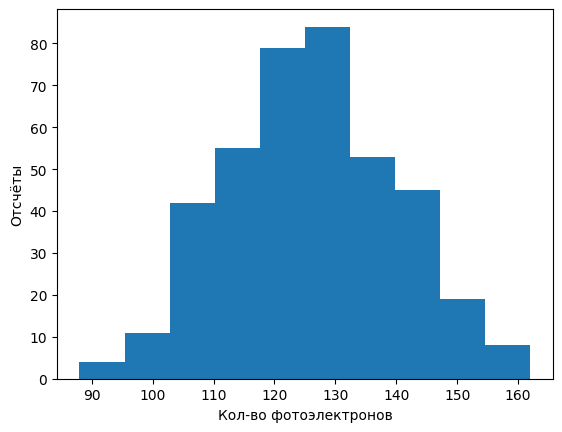

In [13]:
plt.hist(TotalCharge, bins=10)

plt.xlabel('Кол-во фотоэлектронов')
plt.ylabel('Отсчёты')

### Полученное распределение совпадает с результатами задачи 4